## Pooling Layers in CNNs

### Imports and create feature map

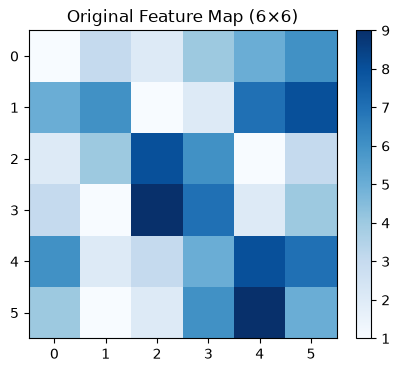

[[1. 3. 2. 4. 5. 6.]
 [5. 6. 1. 2. 7. 8.]
 [2. 4. 8. 6. 1. 3.]
 [3. 1. 9. 7. 2. 4.]
 [6. 2. 3. 5. 8. 7.]
 [4. 1. 2. 6. 9. 5.]]


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.layers import MaxPooling2D, AveragePooling2D

feature_map = np.array([
    [1,  3,  2,  4,  5,  6],
    [5,  6,  1,  2,  7,  8],
    [2,  4,  8,  6,  1,  3],
    [3,  1,  9,  7,  2,  4],
    [6,  2,  3,  5,  8,  7],
    [4,  1,  2,  6,  9,  5]
], dtype=np.float32)

plt.figure(figsize=(5, 4))
plt.imshow(feature_map, cmap="Blues")
plt.title("Original Feature Map (6×6)")
plt.colorbar()
plt.show()

print(feature_map)

### Max pooling manually

In [2]:
def max_pooling(image, pool_size=2, stride=2):
    H, W = image.shape
    output = np.zeros((
        (H - pool_size) // stride + 1,
        (W - pool_size) // stride + 1
    ))

    for i in range(output.shape[0]):
        for j in range(output.shape[1]):
            region = image[
                i*stride:i*stride+pool_size,
                j*stride:j*stride+pool_size
            ]
            output[i, j] = np.max(region)

    return output

max_pooled = max_pooling(feature_map)

print("Max Pooling result:\n", max_pooled)
print("Output shape:", max_pooled.shape)

Max Pooling result:
 [[6. 4. 8.]
 [4. 9. 4.]
 [6. 6. 9.]]
Output shape: (3, 3)


### Avg Pooling manually

In [3]:
def average_pooling(image, pool_size=2, stride=2):
    H, W = image.shape
    output = np.zeros((
        (H - pool_size) // stride + 1,
        (W - pool_size) // stride + 1
    ))

    for i in range(output.shape[0]):
        for j in range(output.shape[1]):
            region = image[
                i*stride:i*stride+pool_size,
                j*stride:j*stride+pool_size
            ]
            output[i, j] = np.mean(region)

    return output

avg_pooled = average_pooling(feature_map)

print("Average Pooling result:\n", avg_pooled)
print("Output shape:", avg_pooled.shape)

Average Pooling result:
 [[3.75 2.25 6.5 ]
 [2.5  7.5  2.5 ]
 [3.25 4.   7.25]]
Output shape: (3, 3)


### Results

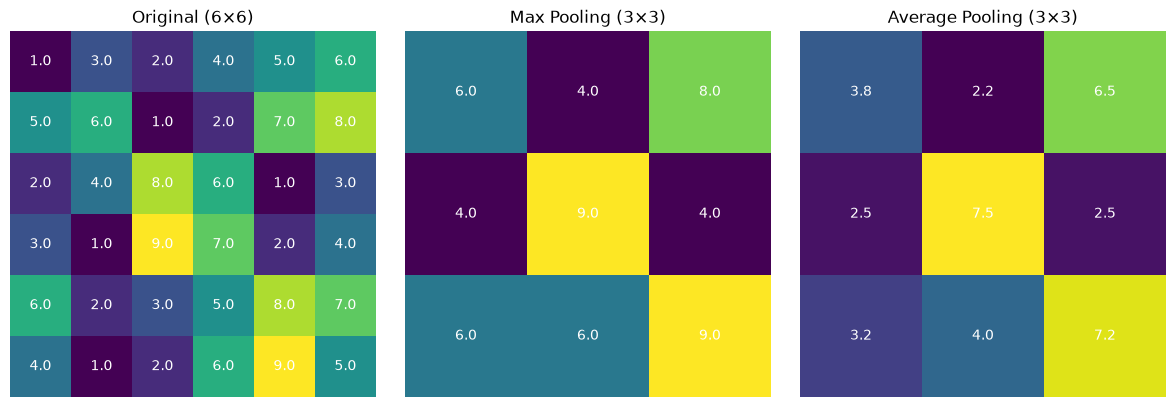

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

data = [
    (feature_map, "Original (6×6)"),
    (max_pooled, "Max Pooling (3×3)"),
    (avg_pooled, "Average Pooling (3×3)")
]

for ax, (matrix, title) in zip(axes, data):
    ax.imshow(matrix, cmap="viridis")
    ax.set_title(title)

    for i in range(matrix.shape[0]):
        for j in range(matrix.shape[1]):
            ax.text(j, i, f"{matrix[i,j]:.1f}",
                    ha="center", va="center", color="white")

    ax.axis("off")

plt.tight_layout()
plt.show()

### Stride changes

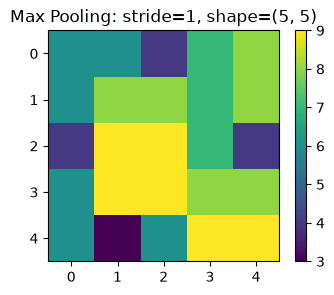

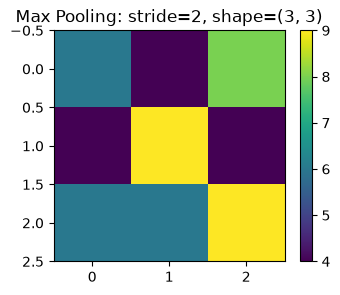

In [5]:
image_tf = tf.constant(feature_map[None, :, :, None])

for stride in [1, 2]:
    layer = MaxPooling2D(
        pool_size=(2, 2),
        strides=(stride, stride),
        padding="valid"
    )

    result = layer(image_tf).numpy()[0, :, :, 0]

    plt.figure(figsize=(4, 3))
    plt.imshow(result, cmap="viridis")
    plt.title(f"Max Pooling: stride={stride}, shape={result.shape}")
    plt.colorbar()
    plt.show()

### Pooling in Keras

In [6]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Input, Conv2D, MaxPooling2D, Flatten, Dense
)

model = Sequential([
    Input(shape=(28, 28, 1)),

    Conv2D(32, (3, 3), activation="relu"),
    MaxPooling2D(pool_size=(2, 2)),

    Conv2D(64, (3, 3), activation="relu"),
    MaxPooling2D(pool_size=(2, 2)),

    Flatten(),
    Dense(64, activation="relu"),
    Dense(10, activation="softmax")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 121,930 (476.29 KB)

 Trainable params: 121,930 (476.29 KB)

 Non-trainable params: 0 (0.00 B)